# Multilingual Reliability of Small LLMs on XQuAD: Accuracy Is Not Enough

Most QA benchmarks report one number. This notebook evaluates a small instruction-tuned LLM (default `Qwen/Qwen2.5-0.5B-Instruct`)
along several reliability axes, in several languages:

- **Correctness:** Exact Match, token F1, fuzzy match
- **Faithfulness:** is the answer a span of the context? Is the cited evidence really in the context? Is the explanation grounded?
- **Language fairness:** is English much better than other languages?
- **Cross-lingual consistency:** XQuAD has the *same* question in every language. Is the model right or wrong consistently?
- **Self-verification:** does a modular *Generator → Verifier → Reviser* pipeline run by the same model beat answering directly?

```
context, question ─► Generator ─► Verifier ──Supported──────────────► final answer
                                     │ Unsupported / Uncertain               ▲
                                     └────────► Reviser ─── corrected ──────┘
```

**Data:** [XQuAD](https://huggingface.co/datasets/google/xquad): 1,190 SQuAD v1.1 dev QA pairs professionally translated into 11 languages, aligned row by row.

In [1]:
%pip install -q torch transformers>=4.56 accelerate datasets pandas tabulate matplotlib numpy tqdm

Note: you may need to restart the kernel to use updated packages.


## 1. Configuration

In [2]:
CONFIG = dict(
    model="Qwen/Qwen2.5-0.5B-Instruct",   # the same model plays generator, verifier and reviser
    langs=["en", "es", "de", "ar", "ru", "zh"],
    n=100,                                 # parallel questions per language (use ~30 on CPU)
    methods=["direct", "modular"],
    revise_on=("Unsupported", "Uncertain"),
    batch_size=8,
    seed=42,
    output_dir="results",
)

## 2. Batched chat generation

In [3]:
import torch
from tqdm.auto import tqdm
from transformers import AutoModelForCausalLM, AutoTokenizer


def _pick_dtype():
    if torch.cuda.is_available():
        return torch.bfloat16 if torch.cuda.is_bf16_supported() else torch.float16
    return torch.float32


class ChatLM:
    def __init__(self, name: str):
        self.name = name
        self.tok = AutoTokenizer.from_pretrained(name)
        self.tok.padding_side = "left"  # required for batched generation
        if self.tok.pad_token is None:
            self.tok.pad_token = self.tok.eos_token
        self.model = AutoModelForCausalLM.from_pretrained(
            name,
            dtype=_pick_dtype(),
            device_map="auto" if torch.cuda.is_available() else None,
        )
        self.model.eval()

    def _render(self, messages: list[dict]) -> str:
        kwargs = dict(tokenize=False, add_generation_prompt=True)
        try:
            # enable_thinking=False turns off "thinking" in Qwen3-style templates;
            # other templates simply ignore the extra variable.
            return self.tok.apply_chat_template(messages, enable_thinking=False, **kwargs)
        except Exception:
            # Some templates (e.g. Gemma) reject the system role: fold it into the user turn.
            if messages and messages[0]["role"] == "system":
                merged = [{"role": "user", "content": messages[0]["content"] + "\n\n" + messages[1]["content"]}]
                return self.tok.apply_chat_template(merged + messages[2:], **kwargs)
            raise

    @torch.no_grad()
    def generate(
        self,
        conversations: list[list[dict]],
        max_new_tokens: int = 512,
        batch_size: int = 8,
        desc: str | None = None,
    ) -> list[str]:
        outputs: list[str] = []
        rng = range(0, len(conversations), batch_size)
        for i in tqdm(rng, desc=desc or self.name, leave=False):
            chunk = conversations[i : i + batch_size]
            prompts = [self._render(m) for m in chunk]
            enc = self.tok(prompts, return_tensors="pt", padding=True, add_special_tokens=False)
            enc = enc.to(self.model.device)
            gen = self.model.generate(
                **enc,
                max_new_tokens=max_new_tokens,
                do_sample=False,  # greedy -> reproducible judgements
                temperature=None,
                top_p=None,
                top_k=None,
                pad_token_id=self.tok.pad_token_id,
            )
            new_tokens = gen[:, enc["input_ids"].shape[1] :]
            outputs.extend(t.strip() for t in self.tok.batch_decode(new_tokens, skip_special_tokens=True))
        return outputs

    def unload(self) -> None:
        del self.model
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

## 3. Parallel multilingual data

In [4]:
import random

from datasets import load_dataset

# Languages available in google/xquad
XQUAD_LANGS = ["ar", "de", "el", "en", "es", "hi", "ro", "ru", "th", "tr", "vi", "zh"]


def load_parallel_xquad(langs: list[str], n: int, seed: int = 42) -> dict[str, list[dict]]:
    """Return {lang: [item, ...]} where item i is the *same* question in every language.

    XQuAD is a professional translation of 1,190 SQuAD v1.1 dev pairs, and the rows are
    aligned across languages (same id and same order). We sample n aligned indices.
    """
    bad = set(langs) - set(XQUAD_LANGS)
    if bad:
        raise ValueError(f"Unsupported languages {bad}; choose from {XQUAD_LANGS}")

    splits = {l: load_dataset("google/xquad", f"xquad.{l}", split="validation") for l in langs}
    size = min(len(d) for d in splits.values())
    ref = splits[langs[0]]

    # Prefer id-based alignment; fall back to row order if ids differ between configs.
    id_maps = {l: {row_id: i for i, row_id in enumerate(d["id"])} for l, d in splits.items()}
    common = [i for i in ref["id"] if all(i in m for m in id_maps.values())]

    rng = random.Random(seed)
    out: dict[str, list[dict]] = {l: [] for l in langs}
    if len(common) >= n:
        chosen = rng.sample(common, n)
        for l in langs:
            for qid in chosen:
                row = splits[l][id_maps[l][qid]]
                out[l].append(_item(row, l, qid))
    else:
        chosen = rng.sample(range(size), n)
        for l in langs:
            for idx in chosen:
                row = splits[l][idx]
                out[l].append(_item(row, l, f"row{idx}"))
    return out


def _item(row: dict, lang: str, qid: str) -> dict:
    return {
        "id": qid,
        "lang": lang,
        "context": row["context"],
        "question": row["question"],
        "gold_answers": list(dict.fromkeys(row["answers"]["text"])),
    }

## 4. Prompts

Instructions are in English (small models follow them best), but answers must be copied from the context, so they stay in the context's language. Every role returns JSON.

In [5]:
ANSWER_SYSTEM = (
    "You are an extractive question-answering assistant. Answer ONLY using the given context. "
    "The answer must be the shortest exact span copied from the context, in the same language "
    "as the context. Respond with a single JSON object and nothing else:\n"
    '{"answer": "<exact span from the context>", '
    '"evidence": "<the sentence from the context that supports the answer, copied exactly>", '
    '"explanation": "<one short sentence explaining why>"}'
)

ANSWER_USER = "Context:\n{context}\n\nQuestion: {question}\n\nJSON:"

VERIFY_SYSTEM = (
    "You are a strict fact-checker. Given a context, a question and a proposed answer with its "
    "evidence, decide whether the context supports the answer.\n"
    "- Supported: the evidence appears in the context and it clearly answers the question with this answer.\n"
    "- Unsupported: the answer is wrong, not in the context, or the evidence does not support it.\n"
    "- Uncertain: the context is ambiguous or you cannot decide.\n"
    "Respond with a single JSON object and nothing else:\n"
    '{"verdict": "Supported" | "Unsupported" | "Uncertain", "reason": "<one short sentence>"}'
)

VERIFY_USER = (
    "Context:\n{context}\n\nQuestion: {question}\n\n"
    "Proposed answer: {answer}\nEvidence: {evidence}\n\nJSON:"
)

REVISE_SYSTEM = ANSWER_SYSTEM + (
    "\nA previous answer was judged problematic by a fact-checker. Read the feedback, re-read the "
    "context carefully and give a corrected answer."
)

REVISE_USER = (
    "Context:\n{context}\n\nQuestion: {question}\n\n"
    "Previous answer: {answer}\nPrevious evidence: {evidence}\n"
    "Fact-checker verdict: {verdict}. Reason: {reason}\n\nCorrected JSON:"
)


def msgs(system: str, user: str) -> list[dict]:
    return [{"role": "system", "content": system}, {"role": "user", "content": user}]

## 5. Direct baseline and modular pipeline

In [6]:
import json
import re


VERDICTS = ("Supported", "Unsupported", "Uncertain")


def _extract_json(text: str) -> dict | None:
    text = text.strip().strip("`")
    if text.lower().startswith("json"):
        text = text[4:]
    start, end = text.find("{"), text.rfind("}")
    if start != -1 and end > start:
        try:
            obj = json.loads(text[start : end + 1])
            return obj if isinstance(obj, dict) else None
        except json.JSONDecodeError:
            pass
    return None


def _field(text: str, key: str) -> str:
    m = re.search(rf'"{key}"\s*:\s*"((?:[^"\\]|\\.)*)"', text)
    return m.group(1) if m else ""


def parse_answer(text: str) -> dict:
    obj = _extract_json(text)
    if obj is not None:
        res = {k: str(obj.get(k, "") or "").strip() for k in ("answer", "evidence", "explanation")}
        res["parse_ok"] = True
        return res
    # tolerant fallback for truncated / malformed JSON
    ans = _field(text, "answer")
    return {
        "answer": ans or text.strip().split("\n")[0][:200],
        "evidence": _field(text, "evidence"),
        "explanation": _field(text, "explanation"),
        "parse_ok": False,
    }


def parse_verdict(text: str) -> dict:
    obj = _extract_json(text) or {}
    raw = str(obj.get("verdict", "")) or text
    low = raw.lower()
    # check "unsupported" before "supported" (substring!)
    if "unsupported" in low or "not supported" in low:
        verdict = "Unsupported"
    elif "supported" in low:
        verdict = "Supported"
    else:
        verdict = "Uncertain"
    return {"verdict": verdict, "reason": str(obj.get("reason", "")).strip()}


def run_direct(lm: ChatLM, items: list[dict], batch_size: int = 8) -> list[dict]:
    prompts = [msgs(ANSWER_SYSTEM, ANSWER_USER.format(**it)) for it in items]
    outs = lm.generate(prompts, max_new_tokens=192, batch_size=batch_size, desc="direct")
    return [{**it, **parse_answer(o), "raw": o} for it, o in zip(items, outs)]


def run_modular(
    lm: ChatLM,
    items: list[dict],
    batch_size: int = 8,
    revise_on: tuple[str, ...] = ("Unsupported", "Uncertain"),
) -> list[dict]:
    # 1) Generator
    gen = run_direct(lm, items, batch_size)

    # 2) Verifier
    vprompts = [
        msgs(VERIFY_SYSTEM, VERIFY_USER.format(context=g["context"], question=g["question"],
                                               answer=g["answer"], evidence=g["evidence"] or "(none)"))
        for g in gen
    ]
    vouts = lm.generate(vprompts, max_new_tokens=96, batch_size=batch_size, desc="verify")
    verdicts = [parse_verdict(v) for v in vouts]

    # 3) Reviser (only where the verifier objected)
    to_fix = [i for i, v in enumerate(verdicts) if v["verdict"] in revise_on]
    rprompts = [
        msgs(REVISE_SYSTEM, REVISE_USER.format(
            context=gen[i]["context"], question=gen[i]["question"], answer=gen[i]["answer"],
            evidence=gen[i]["evidence"] or "(none)", verdict=verdicts[i]["verdict"],
            reason=verdicts[i]["reason"] or "n/a"))
        for i in to_fix
    ]
    routs = lm.generate(rprompts, max_new_tokens=192, batch_size=batch_size, desc="revise") if rprompts else []
    revised = dict(zip(to_fix, (parse_answer(r) for r in routs)))

    results = []
    for i, (g, v) in enumerate(zip(gen, verdicts)):
        row = {
            **{k: g[k] for k in ("id", "lang", "context", "question", "gold_answers")},
            "initial_answer": g["answer"],
            "initial_evidence": g["evidence"],
            "initial_explanation": g["explanation"],
            "verdict": v["verdict"],
            "verifier_reason": v["reason"],
            "revised": i in revised,
        }
        final = revised.get(i, g)
        row.update(answer=final["answer"], evidence=final["evidence"],
                   explanation=final["explanation"], parse_ok=final["parse_ok"])
        results.append(row)
    return results

## 6. Metrics

| Metric | Definition |
|---|---|
| EM / F1 | SQuAD-style after Unicode-aware normalisation; character-level for `zh`/`th` |
| Fuzzy | `difflib` similarity to the closest gold answer |
| Answer-in-context | answer is a verbatim span of the context |
| Evidence faithfulness | 1 if evidence is a verbatim span of the context, else coverage of its longest matching block |
| Explanation faithfulness | share of explanation content tokens found in context / question / answer |
| Language bias | best/worst language, max–min gap, std, English − non-English mean |
| Cross-lingual consistency | per parallel question, agreement on correctness (F1 ≥ 0.5) across language pairs |

In [7]:
import itertools
import re
import statistics
import unicodedata
from collections import Counter, defaultdict
from difflib import SequenceMatcher

# Scripts written without spaces: score F1 at character level.
CHAR_LEVEL_LANGS = {"zh", "th", "ja"}
CORRECT_F1 = 0.5  # threshold used for "correct" in consistency metrics


# ---------------------------------------------------------------- normalisation
def normalize(text: str, lang: str) -> str:
    text = unicodedata.normalize("NFKC", text or "").lower()
    text = "".join(ch if not unicodedata.category(ch).startswith("P") else " " for ch in text)
    if lang == "en":
        text = re.sub(r"\b(a|an|the)\b", " ", text)
    return " ".join(text.split())


def tokens(text: str, lang: str) -> list[str]:
    norm = normalize(text, lang)
    return list(norm.replace(" ", "")) if lang in CHAR_LEVEL_LANGS else norm.split()


# ---------------------------------------------------------------- answer metrics
def exact_match(pred: str, golds: list[str], lang: str) -> float:
    p = normalize(pred, lang)
    return float(any(p == normalize(g, lang) for g in golds))


def _f1(pred_toks: list[str], gold_toks: list[str]) -> float:
    common = Counter(pred_toks) & Counter(gold_toks)
    same = sum(common.values())
    if not pred_toks or not gold_toks:
        return float(pred_toks == gold_toks)
    if same == 0:
        return 0.0
    p, r = same / len(pred_toks), same / len(gold_toks)
    return 2 * p * r / (p + r)


def f1(pred: str, golds: list[str], lang: str) -> float:
    pt = tokens(pred, lang)
    return max(_f1(pt, tokens(g, lang)) for g in golds)


def fuzzy(pred: str, golds: list[str], lang: str) -> float:
    p = normalize(pred, lang)
    return max(SequenceMatcher(None, p, normalize(g, lang)).ratio() for g in golds)


# ---------------------------------------------------------------- faithfulness
def evidence_faithfulness(evidence: str, context: str, lang: str) -> float:
    """1.0 if the evidence is a verbatim span of the context, otherwise the share of the
    evidence covered by its longest common block with the context (0 if empty)."""
    e, c = normalize(evidence, lang), normalize(context, lang)
    if not e:
        return 0.0
    if e in c:
        return 1.0
    m = SequenceMatcher(None, e, c, autojunk=False).find_longest_match(0, len(e), 0, len(c))
    return m.size / len(e)


def answer_in_context(answer: str, context: str, lang: str) -> float:
    a = normalize(answer, lang)
    return float(bool(a) and a in normalize(context, lang))


def explanation_faithfulness(explanation: str, answer: str, context: str, question: str, lang: str) -> float:
    """Share of the explanation's content tokens that are grounded in the context or
    question. Explanations that introduce outside facts score low."""
    exp = [t for t in tokens(explanation, lang) if lang in CHAR_LEVEL_LANGS or len(t) > 2]
    if not exp:
        return 0.0
    support = set(tokens(context, lang)) | set(tokens(question, lang)) | set(tokens(answer, lang))
    return sum(t in support for t in exp) / len(exp)


# ---------------------------------------------------------------- per-row + aggregates
def score_row(r: dict) -> dict:
    lang = r["lang"]
    return {
        "em": exact_match(r["answer"], r["gold_answers"], lang),
        "f1": f1(r["answer"], r["gold_answers"], lang),
        "fuzzy": fuzzy(r["answer"], r["gold_answers"], lang),
        "answer_in_context": answer_in_context(r["answer"], r["context"], lang),
        "evidence_faithfulness": evidence_faithfulness(r.get("evidence", ""), r["context"], lang),
        "explanation_faithfulness": explanation_faithfulness(
            r.get("explanation", ""), r["answer"], r["context"], r["question"], lang),
        "json_parse_ok": float(bool(r.get("parse_ok"))),
    }


def _mean(xs):
    xs = list(xs)
    return round(sum(xs) / len(xs), 4) if xs else None


def aggregate(rows: list[dict]) -> dict:
    keys = rows[0]["scores"].keys()
    out = {k: _mean(r["scores"][k] for r in rows) for k in keys}
    if "verdict" in rows[0]:
        vc = Counter(r["verdict"] for r in rows)
        out["verdicts"] = {v: round(vc[v] / len(rows), 4) for v in ("Supported", "Unsupported", "Uncertain")}
        out["revision_rate"] = _mean(float(r["revised"]) for r in rows)
        # did revising help on the rows that were revised?
        rev = [r for r in rows if r["revised"]]
        if rev:
            out["f1_before_revision_on_revised"] = _mean(f1(r["initial_answer"], r["gold_answers"], r["lang"]) for r in rev)
            out["f1_after_revision_on_revised"] = _mean(r["scores"]["f1"] for r in rev)
        # how well does the verifier's verdict track actual correctness of the initial answer?
        sup = [r for r in rows if r["verdict"] == "Supported"]
        uns = [r for r in rows if r["verdict"] == "Unsupported"]
        out["initial_f1_when_supported"] = _mean(f1(r["initial_answer"], r["gold_answers"], r["lang"]) for r in sup)
        out["initial_f1_when_unsupported"] = _mean(f1(r["initial_answer"], r["gold_answers"], r["lang"]) for r in uns)
    return out


def language_bias(per_lang: dict[str, dict], metric: str = "f1") -> dict:
    vals = {l: m[metric] for l, m in per_lang.items()}
    non_en = [v for l, v in vals.items() if l != "en"]
    res = {
        "metric": metric,
        "best_language": max(vals, key=vals.get),
        "worst_language": min(vals, key=vals.get),
        "max_min_gap": round(max(vals.values()) - min(vals.values()), 4),
        "std_across_languages": round(statistics.pstdev(vals.values()), 4),
    }
    if "en" in vals and non_en:
        res["english_minus_non_english_mean"] = round(vals["en"] - sum(non_en) / len(non_en), 4)
    return res


def cross_lingual_consistency(rows_by_lang: dict[str, list[dict]]) -> dict:
    """For each parallel question, do the languages agree on whether the model got it right?"""
    correct = defaultdict(dict)
    for lang, rows in rows_by_lang.items():
        for r in rows:
            correct[r["id"]][lang] = r["scores"]["f1"] >= CORRECT_F1
    langs = list(rows_by_lang)
    pair_agree, all_right, all_wrong = [], 0, 0
    for qid, d in correct.items():
        if len(d) != len(langs):
            continue
        vals = [d[l] for l in langs]
        all_right += all(vals)
        all_wrong += not any(vals)
        pair_agree.append(_mean(float(a == b) for a, b in itertools.combinations(vals, 2)))
    n = len(pair_agree)
    pairwise = {
        f"{a}-{b}": _mean(float(correct[q][a] == correct[q][b]) for q in correct if a in correct[q] and b in correct[q])
        for a, b in itertools.combinations(langs, 2)
    }
    return {
        "mean_pairwise_agreement": _mean(pair_agree),
        "all_languages_correct": round(all_right / n, 4) if n else None,
        "all_languages_wrong": round(all_wrong / n, 4) if n else None,
        "per_language_pair": pairwise,
    }

## 7. Run the evaluation

In [8]:
import json
from pathlib import Path
import pandas as pd

out = Path(CONFIG["output_dir"]); (out / "predictions").mkdir(parents=True, exist_ok=True)
data = load_parallel_xquad(CONFIG["langs"], CONFIG["n"], CONFIG["seed"])
print({l: len(v) for l, v in data.items()})
print("Example (de):", data["de"][0]["question"] if "de" in data else data[CONFIG["langs"][0]][0]["question"])
lm = ChatLM(CONFIG["model"])

README.md:   0%|          | 0.00/15.6k [00:00<?, ?B/s]

xquad.en/validation-00000-of-00001.parqu(…): reconstructing file:   0%|          |  0.00B /  212kB            

xquad.en/validation-00000-of-00001.parqu(…): downloading bytes:           |  0.00B            

Generating validation split:   0%|          | 0/1190 [00:00<?, ? examples/s]

xquad.es/validation-00000-of-00001.parqu(…): reconstructing file:   0%|          |  0.00B /  237kB            

...

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  988MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

In [9]:
report = {"model": CONFIG["model"], "n_per_language": CONFIG["n"], "languages": CONFIG["langs"], "methods": {}}
all_predictions = {}

for method in CONFIG["methods"]:
    rows_by_lang = {}
    for lang in CONFIG["langs"]:
        print(f"[{method}] {lang}")
        rows = run_direct(lm, data[lang], CONFIG["batch_size"]) if method == "direct" else \
               run_modular(lm, data[lang], CONFIG["batch_size"], tuple(CONFIG["revise_on"]))
        for r in rows:
            r["scores"] = score_row(r)
            r.pop("raw", None)
        rows_by_lang[lang] = rows
        with open(out / "predictions" / f"{method}_{lang}.jsonl", "w", encoding="utf-8") as f:
            for r in rows:
                f.write(json.dumps({k: v for k, v in r.items() if k != "context"}, ensure_ascii=False) + "\n")
    all_predictions[method] = rows_by_lang
    per_lang = {l: aggregate(rows) for l, rows in rows_by_lang.items()}
    report["methods"][method] = {
        "overall": aggregate([r for rows in rows_by_lang.values() for r in rows]),
        "per_language": per_lang,
        "language_bias_f1": language_bias(per_lang, "f1"),
        "language_bias_em": language_bias(per_lang, "em"),
        "cross_lingual_consistency": cross_lingual_consistency(rows_by_lang),
    }
(out / "metrics.json").write_text(json.dumps(report, indent=2, ensure_ascii=False))

[direct] en


direct:   0%|          | 0/13 [00:00<?, ?it/s]

[direct] es


direct:   0%|          | 0/13 [00:00<?, ?it/s]

[direct] de


...

revise:   0%|          | 0/1 [00:00<?, ?it/s]

[modular] zh


direct:   0%|          | 0/13 [00:00<?, ?it/s]

verify:   0%|          | 0/13 [00:00<?, ?it/s]

8052

## 8. Results

In [10]:
COLS = ["em", "f1", "fuzzy", "answer_in_context", "evidence_faithfulness", "explanation_faithfulness", "json_parse_ok"]
md_parts = []
for method, res in report["methods"].items():
    df = pd.DataFrame(res["per_language"]).T[COLS]
    df.loc["ALL"] = [res["overall"][c] for c in COLS]
    print(f"\n=== {method} ===")
    display(df.astype(float).round(3))
    md_parts.append(f"## {method}\n\n" + df.astype(float).round(3).to_markdown())
(out / "summary.md").write_text("\n\n".join(md_parts) + "\n")

pd.DataFrame({m: {**{f"bias_{k}": v for k, v in r["language_bias_f1"].items() if k != "metric"},
                  **{k: v for k, v in r["cross_lingual_consistency"].items() if k != "per_language_pair"}}
              for m, r in report["methods"].items()})


=== direct ===


,em,f1,fuzzy,answer_in_context,evidence_faithfulness,explanation_faithfulness,json_parse_ok
en,0.480,0.655,0.731,0.900,0.859,0.667,0.98
es,0.310,0.496,0.593,0.780,0.810,0.564,0.90
de,0.330,0.483,0.599,0.790,0.800,0.626,0.95
ar,0.220,0.342,0.538,0.690,0.653,0.510,0.85
ru,0.220,0.355,0.514,0.600,0.788,0.476,0.76
zh,0.580,0.753,0.751,0.820,0.786,0.814,0.96
ALL,0.357,0.514,0.621,0.763,0.783,0.609,0.90



=== modular ===


,em,f1,fuzzy,answer_in_context,evidence_faithfulness,explanation_faithfulness,json_parse_ok
en,0.480,0.655,0.731,0.900,0.859,0.667,0.980
es,0.310,0.496,0.594,0.780,0.818,0.564,0.910
de,0.330,0.483,0.599,0.790,0.800,0.626,0.950
ar,0.220,0.342,0.538,0.690,0.653,0.510,0.850
ru,0.230,0.371,0.532,0.620,0.791,0.479,0.780
zh,0.580,0.753,0.751,0.820,0.786,0.814,0.960
ALL,0.358,0.517,0.624,0.767,0.784,0.610,0.905


,direct,modular
bias_best_language,zh,zh
bias_worst_language,ar,ar
bias_max_min_gap,0.4106,0.4106
bias_std_across_languages,0.149,0.1461
bias_english_minus_non_english_mean,0.1692,0.1659
mean_pairwise_agreement,0.6054,0.6107
all_languages_correct,0.11,0.12
all_languages_wrong,0.07,0.07


### Did the verifier help?

In [11]:
if "modular" in report["methods"]:
    o = report["methods"]["modular"]["overall"]
    print("Verdict distribution:", o["verdicts"])
    print("Revision rate:", o["revision_rate"])
    print("F1 on revised rows: before", o.get("f1_before_revision_on_revised"), "-> after", o.get("f1_after_revision_on_revised"))
    print("Initial F1 when verifier said Supported:", o["initial_f1_when_supported"],
          "| Unsupported:", o["initial_f1_when_unsupported"])
    display(pd.DataFrame({l: v["verdicts"] for l, v in report["methods"]["modular"]["per_language"].items()}).T)

Verdict distribution: {'Supported': 0.995, 'Unsupported': 0.005, 'Uncertain': 0.0}
Revision rate: 0.005
F1 on revised rows: before 0.0 -> after 0.5556
Initial F1 when verifier said Supported: 0.5165 | Unsupported: 0.0


,Supported,Unsupported,Uncertain
en,1.00,0.00,0.0
es,0.99,0.01,0.0
de,1.00,0.00,0.0
ar,1.00,0.00,0.0
ru,0.98,0.02,0.0
zh,1.00,0.00,0.0


### Charts

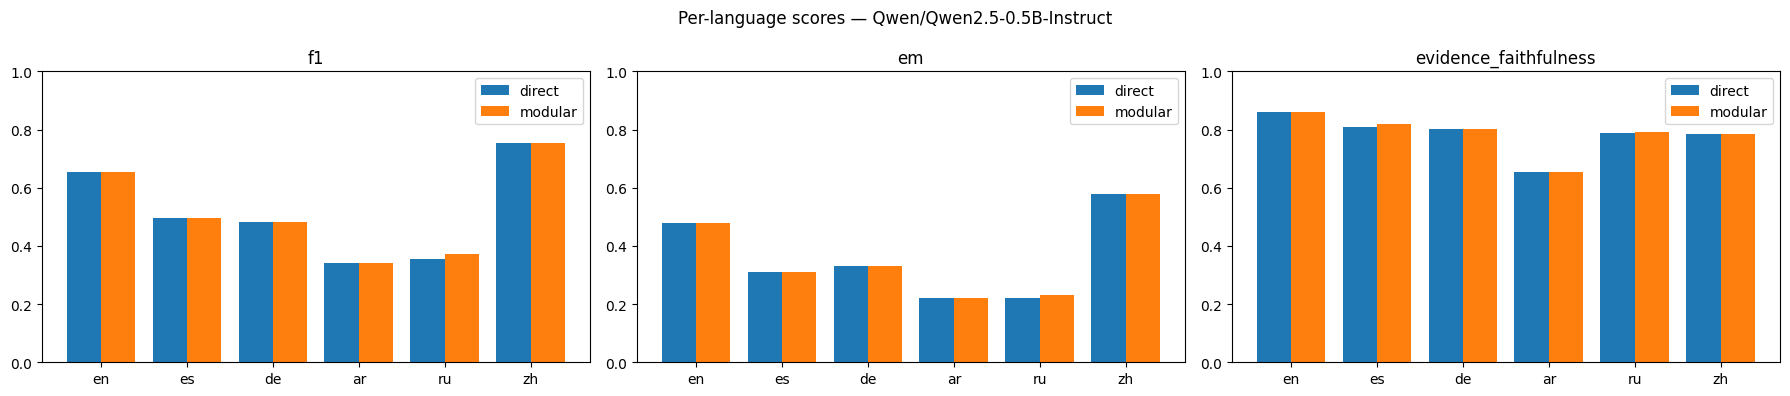

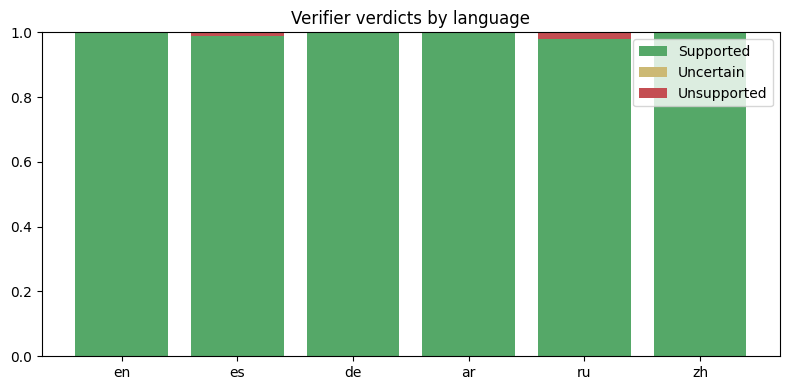

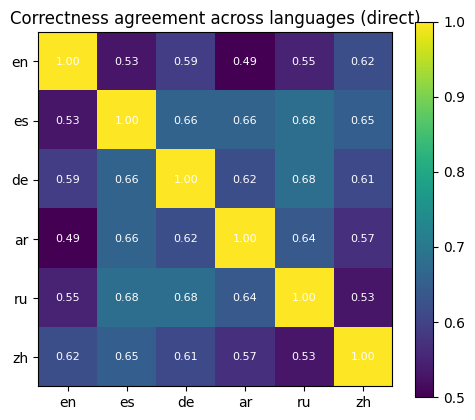

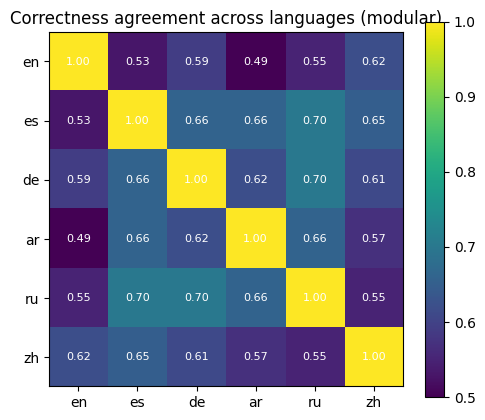

In [12]:
import matplotlib.pyplot as plt
import numpy as np

methods, langs = list(report["methods"]), report["languages"]
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
for ax, metric in zip(axes, ("f1", "em", "evidence_faithfulness")):
    w = 0.8 / len(methods); x = np.arange(len(langs))
    for k, m in enumerate(methods):
        ax.bar(x + k * w - 0.4 + w / 2, [report["methods"][m]["per_language"][l][metric] for l in langs], w, label=m)
    ax.set_xticks(x, langs); ax.set_ylim(0, 1); ax.set_title(metric); ax.legend()
fig.suptitle(f"Per-language scores — {report['model']}")
fig.tight_layout(); fig.savefig(out / "scores_by_language.png", dpi=150); plt.show()

if "modular" in report["methods"]:
    per = report["methods"]["modular"]["per_language"]
    fig, ax = plt.subplots(figsize=(8, 4)); bottom = np.zeros(len(langs))
    for v, c in (("Supported", "#55A868"), ("Uncertain", "#CCB974"), ("Unsupported", "#C44E52")):
        vals = np.array([per[l]["verdicts"][v] for l in langs])
        ax.bar(langs, vals, bottom=bottom, label=v, color=c); bottom += vals
    ax.set_title("Verifier verdicts by language"); ax.legend()
    fig.tight_layout(); fig.savefig(out / "verifier_verdicts.png", dpi=150); plt.show()

for m in methods:
    pairs = report["methods"][m]["cross_lingual_consistency"]["per_language_pair"]
    mat = np.eye(len(langs))
    for key, v in pairs.items():
        a, b = key.split("-"); i, j = langs.index(a), langs.index(b); mat[i, j] = mat[j, i] = v
    fig, ax = plt.subplots(figsize=(5, 4.3))
    im = ax.imshow(mat, vmin=0.5, vmax=1, cmap="viridis")
    ax.set_xticks(range(len(langs)), langs); ax.set_yticks(range(len(langs)), langs)
    for i in range(len(langs)):
        for j in range(len(langs)):
            ax.text(j, i, f"{mat[i, j]:.2f}", ha="center", va="center", color="w", fontsize=8)
    fig.colorbar(im); ax.set_title(f"Correctness agreement across languages ({m})")
    fig.tight_layout(); fig.savefig(out / f"consistency_heatmap_{m}.png", dpi=150); plt.show()

### Error analysis: one question across languages

In [13]:
m = CONFIG["methods"][-1]
qid = all_predictions[m][CONFIG["langs"][0]][0]["id"]
for lang in CONFIG["langs"]:
    r = next(x for x in all_predictions[m][lang] if x["id"] == qid)
    print(f"[{lang}] Q: {r['question']}\n     gold={r['gold_answers'][0]!r}  pred={r['answer']!r}  F1={r['scores']['f1']:.2f}"
          + (f"  verdict={r['verdict']} revised={r['revised']}" if "verdict" in r else ""))

[en] Q: What is the proprietary system that Sky+HD uses?
     gold='OpenTV'  pred='OpenTV'  F1=1.00  verdict=Supported revised=False
[es] Q: ¿Cuál es el sistema comercial que utiliza Sky+HD?
     gold='OpenTV'  pred='OpenTV'  F1=1.00  verdict=Supported revised=False
[de] Q: Welches proprietäre System verwendet Sky+HD?
     gold='OpenTV'  pred='OpenTV'  F1=1.00  verdict=Supported revised=False
[ar] Q: ما هو نظام الملكية الذي تستعمله سكاي بلس إتش دي؟
     gold='أوبن تي في'  pred='أوبن تي في'  F1=1.00  verdict=Supported revised=False
[ru] Q: Какую проприетарную систему использует Sky+HD?
     gold='OpenTV'  pred='OpenTV'  F1=1.00  verdict=Supported revised=False
[zh] Q: Sky+HD使用的专有系统是什么？
     gold='OpenTV'  pred='OpenTV'  F1=1.00  verdict=Supported revised=False


## 9. Discussion

- **Why accuracy isn't enough:** two systems with equal F1 can differ widely in whether their evidence and explanations are real.
- **Did verification help?** Compare F1 before/after revision on revised rows, and whether "Supported" answers really are more accurate than "Unsupported" ones. If not, the verifier isn't discriminating.
- **One model as generator and verifier:** errors are correlated (the verifier shares the generator's blind spots), a 0.5B model has limited judging ability, and the pipeline costs 2–3× the compute.
- **Language bias as a fairness issue:** if non-English users systematically get worse, less faithful answers, that is an equity problem, not just a benchmark artefact.

**References:** HELM ([arXiv:2211.09110](https://arxiv.org/abs/2211.09110)) · DecodingTrust ([arXiv:2306.11698](https://arxiv.org/abs/2306.11698)) · SelfCheckGPT ([arXiv:2303.08896](https://arxiv.org/abs/2303.08896)) · XQuAD ([arXiv:1910.11856](https://arxiv.org/abs/1910.11856))

*Developed as part of the Large Language Models course, University of Tehran (Spring 2026).*

In [14]:
!zip -r results.zip results


  adding: results/ (stored 0%)
  adding: results/consistency_heatmap_modular.png (deflated 9%)
  adding: results/consistency_heatmap_direct.png (deflated 8%)
  adding: results/scores_by_language.png (deflated 27%)
  adding: results/metrics.json (deflated 86%)
  adding: results/verifier_verdicts.png (deflated 22%)
  adding: results/summary.md (deflated 82%)
  adding: results/predictions/ (stored 0%)
  adding: results/predictions/direct_ru.jsonl (deflated 78%)
  adding: results/predictions/modular_es.jsonl (deflated 82%)
  adding: results/predictions/direct_ar.jsonl (deflated 78%)
  adding: results/predictions/modular_ar.jsonl (deflated 82%)
  adding: results/predictions/modular_de.jsonl (deflated 81%)
  adding: results/predictions/modular_zh.jsonl (deflated 80%)
  adding: results/predictions/direct_es.jsonl (deflated 76%)
  adding: results/predictions/direct_en.jsonl (deflated 77%)
  adding: results/predictions/modular_en.jsonl (deflated 84%)
  adding: results/predictions/modular_ru.jso